# Explore the data and its recorded origins
Compute and export a result, select part of it with xarray, and inspect the
server's recorded relationships. This demonstrates current local analysis work,
not a merged release. The 5 × 4 TEST field is synthetic, not real terrain.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from klab_client import (connect, ObservationRequest, RectangularGeometry,
                         export_for_analysis, open_raster, fetch_provenance, trace_analysis)
from notebook_setup import profile, certificate, track_session, reset_field, plot_recorded_links

connection = connect(profile(), credentials=certificate())
client = connection.client
session = client.create_session(name="Notebook: analyze and trace")
track_session(session)
context = session.create_context()
region = context.observe(ObservationRequest("earth:Region",
    geometry=RectangularGeometry(200000, 200500, 6000000, 6000400, 5, 4))).result(120)
reset_field()
observation = context.within(region).observe("geography:Aspect in degree_angle").result(120)
artifact = export_for_analysis(observation, "field.tif")
analysis = open_raster(artifact)
ds = analysis.dataset
display(ds)

<xarray.Dataset> Size: 252B
Dimensions:  (y: 4, x: 5)
Coordinates:
  * y        (y) float64 32B 6e+06 6e+06 6e+06 6e+06
  * x        (x) float64 40B 2e+05 2.002e+05 2.002e+05 2.004e+05 2.004e+05
Data variables:
    value    (y, x) float64 160B 3.0 13.0 23.0 33.0 43.0 ... 10.0 20.0 30.0 40.0
    valid    (y, x) bool 20B True True True True True ... True True True True

## Select part of the result
Here we keep the eastern three columns. xarray keeps their original coordinates.
Missing cells are masked, but a valid zero is still a number.

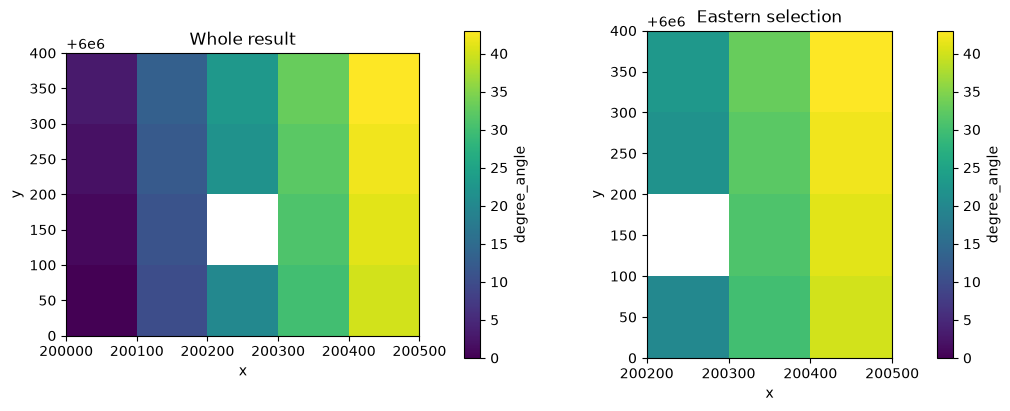

,area,valid cells,min,max
0,Whole grid,19,0.0,43.0
1,East,11,20.0,43.0


In [2]:
values = ds.value.where(ds.valid)
east = values.isel(x=slice(2, None))
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for field, ax, title in [(values, axes[0], "Whole result"), (east, axes[1], "Eastern selection")]:
    field.plot(ax=ax, vmin=0, vmax=43, cbar_kwargs={"label": observation.units})
    ax.set(title=title, aspect="equal")
plt.show()
display(pd.DataFrame([
    {"area": "Whole grid", "valid cells": int(values.count()), "min": float(values.min()), "max": float(values.max())},
    {"area": "East", "valid cells": int(east.count()), "min": float(east.min()), "max": float(east.max())},
]))
assert int(east.count()) == 11 and float(values.sum()) == 409

## Inspect the distribution
These are angles: we do not report a linear mean as though it were a meaningful
average direction. The histogram simply shows the values actually returned.

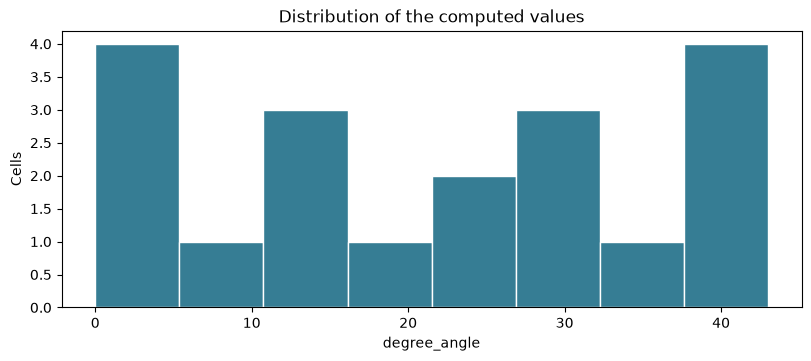

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
values.plot.hist(ax=ax, bins=8, color="#367d94", edgecolor="white")
ax.set(title="Distribution of the computed values", xlabel=observation.units, ylabel="Cells")
plt.show()

## What did the server record around this observation?
Draw the returned relationships and inspect the actual numerical execution.
This is a partial, one-hop view. Identical parallel edges are grouped with a count.

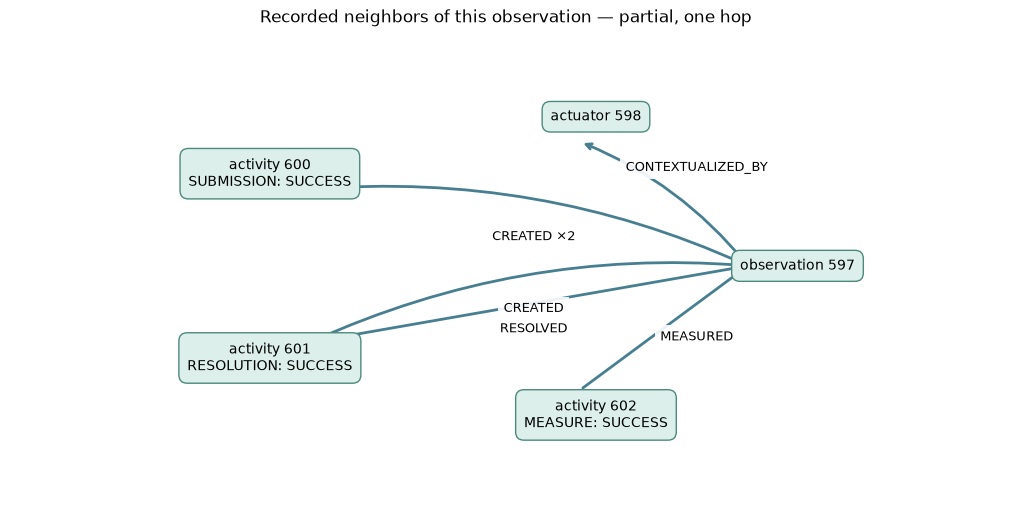

,from,relationship,to,activity,outcome
0,600,CREATED,597,SUBMISSION,SUCCESS
1,600,CREATED,597,SUBMISSION,SUCCESS
2,601,CREATED,597,RESOLUTION,SUCCESS
3,597,CONTEXTUALIZED_BY,598,NaN,NaN
4,601,RESOLVED,597,RESOLUTION,SUCCESS
5,602,MEASURED,597,MEASURE,SUCCESS


In [4]:
view = fetch_provenance(observation)
plot_recorded_links(view)
rows = [{"from": link.source.id, "relationship": link.relationship, "to": link.target.id,
         "activity": link.source.activity_type, "outcome": link.source.outcome}
        for link in view.links]
display(pd.DataFrame(rows))
assert view.partial and any(row["relationship"] == "MEASURED" and row["outcome"] == "SUCCESS" for row in rows)

## Associate the file with that observation
The origin-qualified handles must match. Export and provenance are separate
reads, so this association is not a revision-pinned snapshot or complete lineage.

In [5]:
traced = trace_analysis(analysis, view)
print("Observation:", observation.id, "| file unit:", analysis.descriptor.units)
print("Cross-fetch consistency:", traced.consistency)
refreshed = fetch_provenance(observation)
assert refreshed.fetched_at >= view.fetched_at
assert session.release()
connection.close()

Observation: 597 | file unit: degree_angle
Cross-fetch consistency: unknown: association is not a revision-pinned snapshot
